# 02 · Preprocessing & Feature Extraction

Raw recordings become a labeled feature table with one row per window. Each recording goes
through these steps:

1. **Trim** 1 s from each end (removes start/stop handling).
2. **Validate**: timestamps, missing values, sampling rate ≥ 50 Hz, 5–10 s duration.
3. **Harmonize**: linearly interpolate accelerometer and gyroscope onto one shared 50 Hz grid.
4. **Window**: 2 s windows, 0.5 s step (75 % overlap).
5. **Extract** 56 features per window.

In [1]:
# --- Environment setup (works locally and in Google Colab) ---
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/Orrie-Dan/Human-Activity-HMM.git"
    ROOT = Path("/content/human-activity-hmm")
    if not ROOT.exists():
        !git clone -q {REPO_URL} {ROOT}
    %cd {ROOT}
    !pip install -q -r requirements.txt
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# The recordings are in the repository (data/raw/, data/test/). Fallback only: if
# data/raw/ is empty in Colab, upload a zip of its contents (p01_<activity>_<nn>/ + metadata.csv).
RAW = ROOT / "data" / "raw"
if IN_COLAB and not any(RAW.glob("p*_*_*")):
    import io, zipfile
    from google.colab import files
    for name, content in files.upload().items():
        zipfile.ZipFile(io.BytesIO(content)).extractall(RAW)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.visualization import apply_style

apply_style()
pd.set_option("display.precision", 3)


## Cleaning and resampling

One recording before and after harmonization:

In [3]:
from src.data_loader import load_recording
from src.dataset import process_recording

rec = config.RAW_DATA_DIR / "p01_walking_02"
acc, gyro = load_recording(rec)
signals = process_recording(rec)
print(f"raw: accelerometer {len(acc)} rows, gyroscope {len(gyro)} rows (~100 Hz)")
print(f"harmonized: {len(signals)} rows at {config.DEFAULT_RECORDING_CONFIG.target_sampling_rate_hz:.0f} Hz, "
      f"{signals['timestamp'].iloc[-1]:.2f} s")
signals.head()

raw: accelerometer 1090 rows, gyroscope 1090 rows (~100 Hz)
harmonized: 446 rows at 50 Hz, 8.90 s


,timestamp,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,0.00,-0.149,-0.207,0.127,-0.426,-0.426,0.131
1,0.02,-0.084,-0.296,-0.006,-0.433,-0.383,0.131
2,0.04,-0.275,-0.432,-0.359,-0.386,-0.247,0.234
3,0.06,-0.267,-0.196,0.058,-0.271,-0.010,0.267
4,0.08,-0.138,-0.285,-0.313,-0.064,-0.038,0.229


**Why 50 Hz?** Human movement is concentrated well below 20 Hz (walking and jumping are about
1–3 Hz), so 50 Hz (Nyquist 25 Hz) keeps all the useful information. It is also a rate most
phones can reach, so data from different devices can be put on the same grid.

## Windowing

**Why 2 s windows with a 0.5 s step?** The window is defined in seconds and converted to samples
with the harmonized rate: at 50 Hz, a 2 s window is **100 samples** and the 0.5 s step is
**25 samples**. Because every recording is first resampled to 50 Hz, a window always covers the
same amount of time and the same number of samples, whatever the phone's original rate.

- At about 2 steps or jumps per second, 2 s contains several movement cycles, so mean and
  variance are stable within a window.
- The FFT of 100 samples at 50 Hz has a resolution of 50 / 100 = **0.5 Hz** and reaches up to
  25 Hz. That separates walking (~1 Hz) from jumping (~2 Hz cycle, ~4 Hz in the magnitude).
- Shorter windows (e.g. 1 s) would give a 1 Hz FFT resolution, too coarse to tell walking from
  jumping by frequency. Longer windows would leave the short recordings with almost no windows.

The 0.5 s step gives 9–16 windows for first-session recordings, 2–6 for the short
second-session ones and 5–8 for the third session. Overlapping windows are correlated, which is
why we later split data by recording, never by window.

## Feature extraction

For each of the 8 channels (6 axes plus `acc_mag` and `gyro_mag`) we compute six features, and
for each sensor four more:

| Domain | Feature | Why it separates the activities |
|---|---|---|
| time | **mean** | `acc_mag` mean is the average movement intensity: still ≈ 0 < standing < walking < jumping. Per-axis means capture how the phone is held. |
| time | **std** | Variability within the window. Still has only sensor noise, standing has small hand tremor, walking and jumping have large periodic swings. |
| time | **min, max** | Peaks. Jumping has landing impacts of 20–30 m/s² that no other activity reaches. |
| time | **signal magnitude area (SMA)** | Mean of \|x\|+\|y\|+\|z\|: total movement energy, independent of direction. |
| time | **axis correlations** | How the axes move together. Walking and jumping are periodic, so axes are strongly correlated; for still they are noise and close to 0. |
| frequency | **dominant frequency** (largest non-DC FFT bin) | The movement rhythm: about 1 Hz for walking (one stride), about 4 Hz in the jumping magnitude. |
| frequency | **spectral energy** (FFT power) | How much power the signal has; orders the activities like std, but from the spectrum. |

That gives 8 × 6 + 2 + 6 = **56 features**: 7 kinds of time-domain feature and 2 FFT-derived
frequency-domain features.

In [4]:
from src.dataset import build_feature_table

table, skipped = build_feature_table()
print("skipped:", skipped or "none")
config.FEATURES_FILE.parent.mkdir(parents=True, exist_ok=True)
table.to_csv(config.FEATURES_FILE, index=False)
print(f"{len(table)} windows x {table.shape[1] - 5} features -> {config.FEATURES_FILE.relative_to(ROOT)}")
table.groupby("activity").agg(recordings=("recording", "nunique"), windows=("recording", "size"))

skipped: none
462 windows x 56 features -> data\processed\features.csv


,recordings,windows
activity,,
jumping,13,99
standing,16,104
still,19,133
walking,17,126


## Save processed features

The table above is saved to `data/processed/features.csv`. Below is how the key features are distributed per activity (one dot per window, bar = median). Variability features use a log scale.

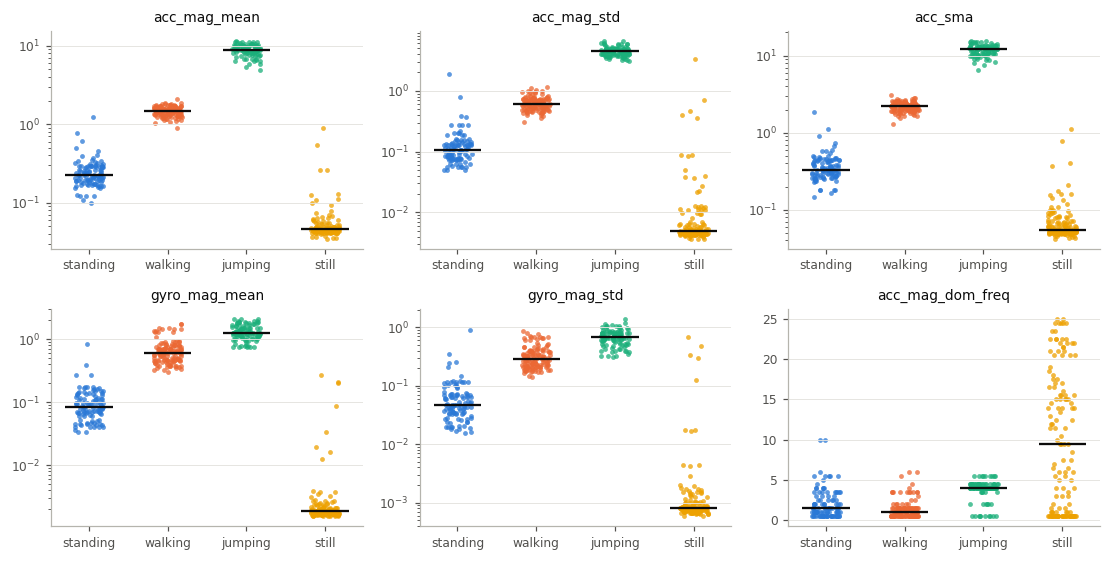

In [5]:
from src.visualization import plot_feature_by_activity

plot_feature_by_activity(
    table,
    ["acc_mag_mean", "acc_mag_std", "acc_sma", "gyro_mag_mean", "gyro_mag_std", "acc_mag_dom_freq"],
    log_scale=["acc_mag_mean", "acc_mag_std", "acc_sma", "gyro_mag_mean", "gyro_mag_std"],
);

- Movement intensity (`acc_mag_mean`, `acc_sma`, `gyro_mag_*`) orders the activities clearly:
  still < standing < walking < jumping, with a factor of about 4–7 between neighbors.
- **standing vs still**, the hardest pair, still differ about 20× in `acc_mag_std` and about
  40–50× in `gyro_mag_mean`. The few still windows near the standing range come from the
  phone being put down (`p01_still_01`, `_02`, `_05`).
- `acc_mag_dom_freq` is about 1 Hz for walking and about 4 Hz for jumping. The magnitude
  probably peaks twice per jump (take-off and landing). For still it is meaningless (the FFT
  of sensor noise, scattered up to 25 Hz), which is one reason a smaller feature set could
  help later.

### Normalization

Features are **not** standardized in this table. In training they are **z-scored**,
$x' = (x - \mu_{\text{train}}) / \sigma_{\text{train}}$, with $\mu$ and $\sigma$ computed on the
training recordings only (inside `train_model`). The same transform is then applied to the
held-out and test windows.

Why z-score:

- The raw features have very different scales. `acc_max` reaches about 30 m/s², correlations
  lie in [-1, 1], and `still`'s `gyro_mag_std` is about 0.001. The HMM's emission variances are
  floored at 1e-3; without scaling, that floor would be huge for some features and negligible
  for others.
- The Gaussian emissions model each feature by a mean and a variance, so centering and scaling
  to unit variance matches that model directly. Min-max scaling would instead be driven by a
  single extreme window, such as one landing spike.
- Fitting the scaler on the training data only keeps information from the test data out of
  the model.